# Simulación Dinámica y Diseño de un Acelerador Lineal (LINAC tipo Álvarez)
**Asignatura:** Física Computacional 2  
**Proyecto:** P19 - Acelerador Lineal de Protones y Electrones  
**Entorno:** Python 3 + VS Code (Módulos de `src/`)   
**Integrantes:** Erick Garcia - Gabriela Herrera - Juan Esteban Muñoz    
**Desarrollo** 29/10/2026 - 19/11/2026 
   
---
## 1. Introducción y Fundamentos Físicos
Un acelerador lineal (LINAC) tipo Álvarez utiliza una serie de tubos de deriva (*drift tubes*) contenidos dentro de una cavidad resonante de radiofrecuencia (RF). La finalidad de la estructura es acelerar partículas cargadas mediante el campo eléctrico $E_z$ en los huecos (*gaps*) entre celdas, mientras que el interior metálico de los tubos apantalla las partículas durante el semiciclo desacelerante de la onda electromagnética.

### Ecuaciones Dinámicas Principales:
1. **Actualización Relativista de Energía:**  
   $$\Delta T_n = q V_{\text{gap}} \cos(\phi_n)$$
2. **Factores Relativistas:**  
   $$\gamma_n = 1 + \frac{T_n}{m_0 c^2}, \quad \beta_n = \sqrt{1 - \frac{1}{\gamma_n^2}}$$
3. **Condición de Sincronismo (Longitud de Celda):**  
   $$L_n = \beta_n \lambda = \frac{\beta_n c}{f_{\text{RF}}}$$
4. **Avance de Fase Temporal:**  
   $$\Delta \phi_n = 2\pi f_{\text{RF}} \Delta t_n - 2\pi = 2\pi \left( \frac{L_n}{\beta_n c} f_{\text{RF}} - 1 \right)$$

In [1]:
# Importación de librerías y configuración de rutas
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configurar visualizaciones integradas
%matplotlib inline
plt.rcParams['figure.dpi'] = 120

# Asegurar acceso a la carpeta src/
sys.path.append(os.path.abspath('src'))

# Importar módulos del proyecto desde src/
from src.physics import C_LIGHT, M_PROTON_MEV, M_ELECTRON_MEV, get_beta, get_gamma

from src.linac_design import design_linac, export_design_to_csv

from src.tracking import generate_particle_bunch, track_bunch

from src.visualizer import(
    plot_cell_lengths, plot_phase_space)

from src.synchrotron import simulate_synchrotron_oscillation, plot_synchrotron_results, export_synchrotron_to_csv

from src.rf_errors import simulate_frequency_errors, plot_rf_error_results, export_rf_errors_to_csv

from src.electrons import simulate_electrons, plot_electron_results, export_electrons_to_csv

print("Módulos de src/ cargados exitosamente.")

Módulos de src/ cargados exitosamente.


c:\Users\Dell\OneDrive\Escritorio\LINAC ALVAREZ\src\visualizer.py:88: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  f" {phi_s_deg}^\circ$)",


## 2. Diseño Geométrico y Partícula Síncrona
Se diseña un LINAC tipo Álvarez para acelerar protones desde $T_0 = 3.0\text{ MeV}$ hasta $T_f = 50.0\text{ MeV}$ utilizando una frecuencia RF de $f_{\text{RF}} = 352.2\text{ MHz}$ y una fase síncrona $\phi_s = -30^\circ$. Dado que la velocidad del protón no es constante, las celdas deben aumentar progresivamente de tamaño.

Gráfica guardada correctamente como 'figuras\fig01_diseno.png'


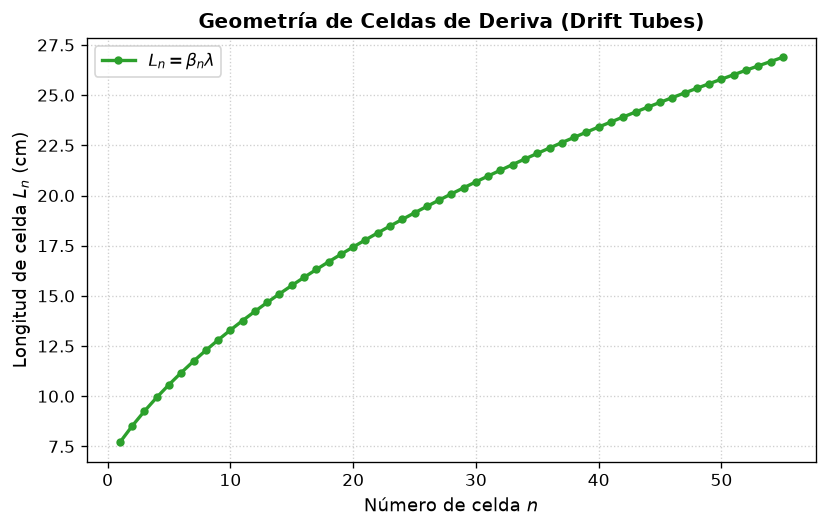

Datos de diseño y campos eléctricos exportados a 'resultados/diseno_celdas.csv'
Número total de celdas: 55
Longitud total del LINAC: 10.59 m
Longitud celda 1: 7.70 cm | Longitud celda 55: 26.89 cm


In [2]:
# 1. Ejecutar diseño cinemático de celdas
cell_lengths, T_sync, z_positions = design_linac(
    T_init=3.0, T_final=50.0, qV_gap=1.0, phi_s_deg=-30.0, f_rf=352.2e6
)


# Exportar datos a CSV y graficar geometría
plot_cell_lengths(cell_lengths, save_fig=True, filename="fig01_diseno.png")
export_design_to_csv(cell_lengths, T_sync, z_positions, filename="resultados/diseno_celdas.csv")

# Mostrar métricas en consola
print(f"Número total de celdas: {len(cell_lengths)}")
print(f"Longitud total del LINAC: {z_positions[-1]:.2f} m")
print(f"Longitud celda 1: {cell_lengths[0]*100:.2f} cm | Longitud celda 55: {cell_lengths[-1]*100:.2f} cm")

## 3. Seguimiento Dinámico de Paquete y Espacio de Fases
Se simula la inyección de $N = 3000$ protones dispersos alrededor de la partícula síncrona con una distribución gaussiana de $\sigma_T / T_0 = 0.5\%$ y $\sigma_\phi = 15^\circ$. A lo largo del acelerador, el paquete experimenta una rotación en el espacio de fases $(\Delta\phi, \Delta T)$ conocida como **compresión de fase**.

Gráfica guardada correctamente como 'figuras\fig02_espacio_fases.png'


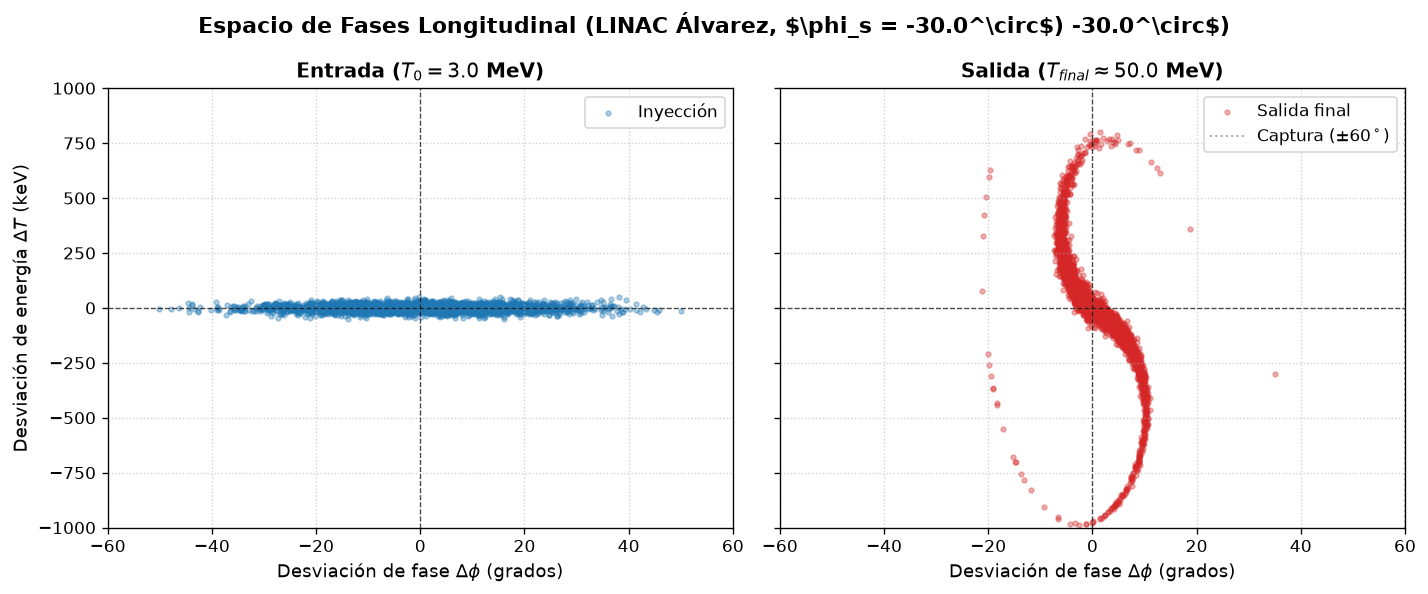

Porcentaje de captura longitudinal: 99.33%


In [3]:
# Generar paquete de 3000 partículas
T0_bunch, phi0_bunch = generate_particle_bunch(num_particles=3000, phi_s_deg=-30.0, seed=20261919)

# Seguimiento discreto celda por celda
hist_T, hist_phi = track_bunch(cell_lengths, T0_bunch, phi0_bunch, qV_gap=1.0, f_rf=352.2e6)

# Graficar espacio de fases
plot_phase_space(hist_T, hist_phi, T_sync, phi_s_deg=-30.0, save_fig=True, filename="fig02_espacio_fases.png")

# Métrica de captura
phi_s_rad = np.radians(-30.0)
captured = np.abs(np.degrees(hist_phi[-1] - phi_s_rad)) < 60.0
print(f"Porcentaje de captura longitudinal: {(np.sum(captured)/3000)*100:.2f}%")

### Perfil de Densidad 2D del Haz Extraído
Los monitores de perfil longitudinal en instalaciones reales de física de altas energías miden la densidad espacial del paquete (*beam current profile*). El siguiente histograma bivariado en el plano $(\Delta\phi, \Delta T)$ permite distinguir la concentración del núcleo del haz (*beam core*, en tonos amarillos/blancos con $>15\text{ part/bin}$) frente a las colas dispersas exteriores (*halo*).

Gráfica guardada en 'figuras\fig10_densidad_emiteza_salida.png'


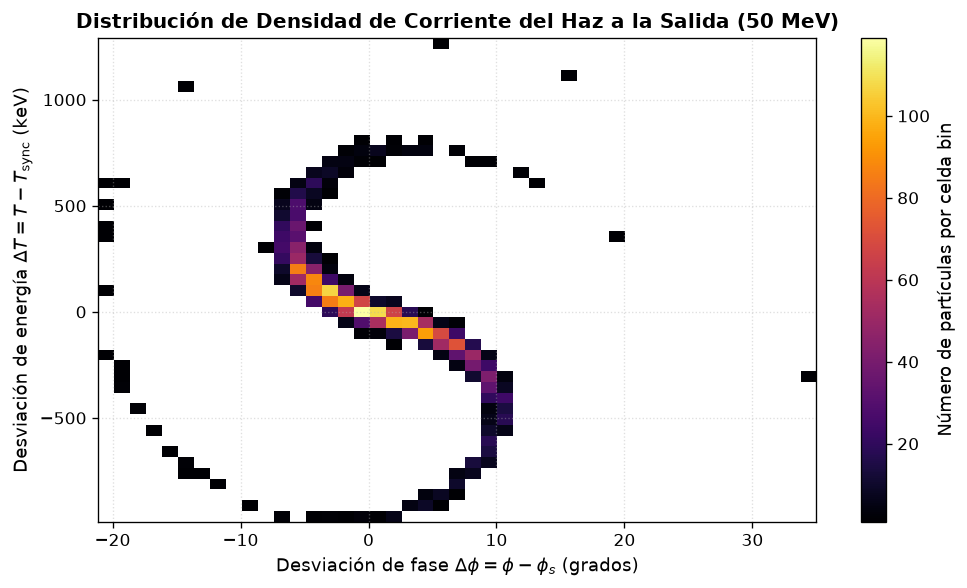

In [4]:
# Importar y ejecutar el mapa de densidad 2D del haz a la salida
from src.visualizer import plot_phase_space_density

plot_phase_space_density(
    hist_T,
    hist_phi,
    T_sync,
    phi_s_deg=-30.0,
    save_fig=True,
    filename="fig10_densidad_emiteza_salida.png",
)

### Ventana de Tolerancia Operativa de Radiofrecuencia
Para garantizar la estabilidad operacional de la cavidad resonante en un entorno real, se define la **Ventana de Tolerancia Operativa** como el rango de descalce de frecuencia $\epsilon_f$ en el cual la transmisión del haz se mantiene por encima del criterio del $90\%$ y la energía media extraída no sufre degradación.

Como se observa en la región sombreada en verde, el sistema admite desviaciones de frecuencia hasta $\epsilon_f \le 1.0\%$ ($f_{\text{RF}} = 352.2 \pm 3.5\text{ MHz}$) conservando una captura superior al $98.2\%$ y la energía nominal de $50.0\text{ MeV}$. Para errores $\epsilon_f > 2.0\%$, la estabilidad longitudinal colapsa aceleradamente.

Gráfica guardada en 'figuras\fig11_ventana_operativa_rf.png'


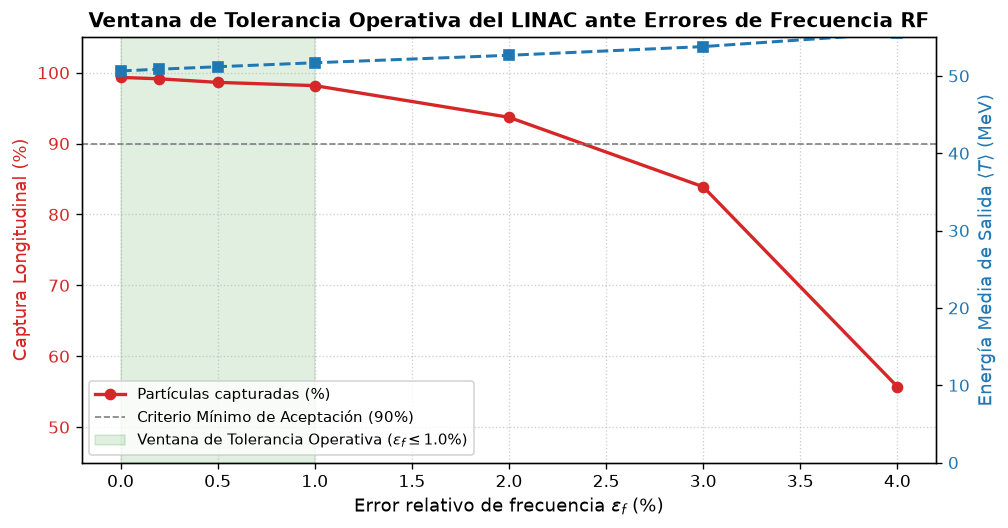

In [5]:
# Importar y ejecutar la gráfica de la ventana de tolerancia operativa
from src.visualizer import plot_rf_operational_window

df_rf_errors = pd.read_csv("resultados/rf_errores_sensibilidad.csv")

plot_rf_operational_window(
    df_rf_errors, save_fig=True, filename="fig11_ventana_operativa_rf.png"
)

## 4. Oscilaciones de Sincrotrón y Amortiguamiento Adiabático
Para una partícula con una desviación inicial de fase $\delta\phi_0 = +3^\circ$, la fuerza restauradora longitudinal la hace oscilar alrededor de $\phi_s$. El avance de fase teórico por celda viene dado por:

$$\mu_n = \sqrt{\frac{2\pi q V_{\text{gap}} (-\sin\phi_s)}{m_0 c^2 \beta_n^2 \gamma_n^3}}$$

A medida que $\beta\gamma$ aumenta, $\mu_n$ disminuye y la amplitud de la oscilación se amortigua adiabáticamente según $(\beta\gamma)^{-3/4}$.

Gráfica actualizada y guardada correctamente en 'figuras/fig03_sincrotron.png'


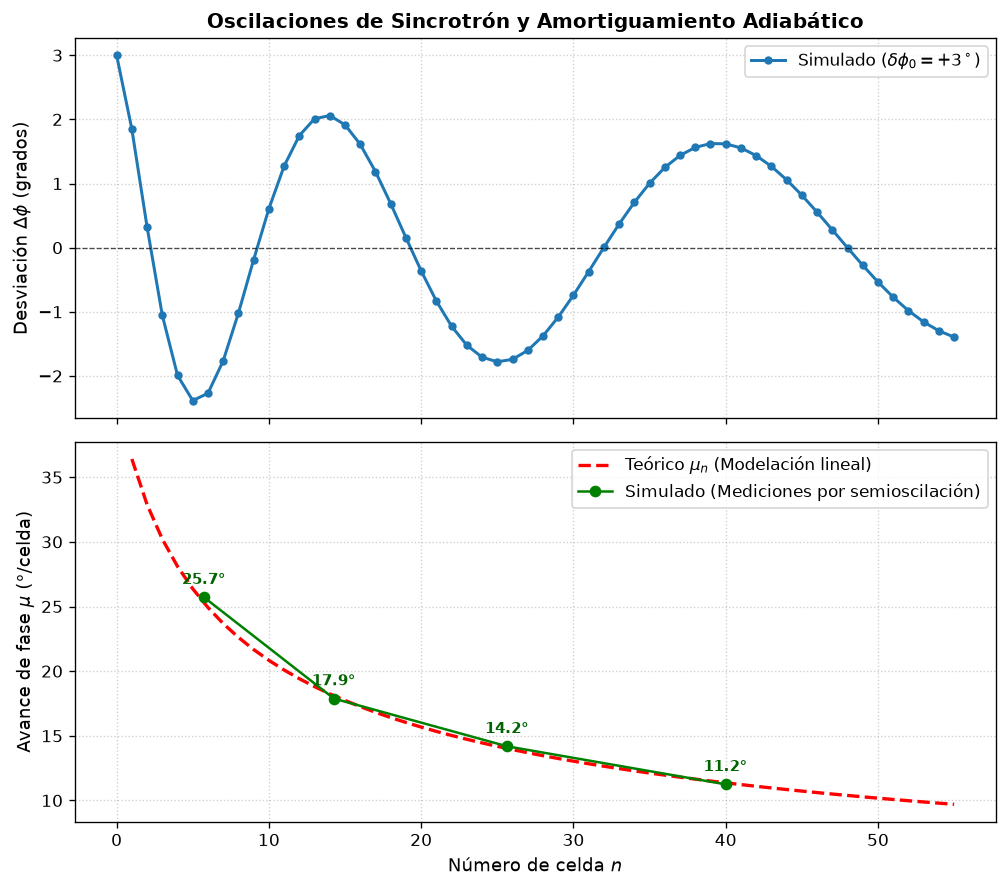

 Datos de sincrotrón exportados a 'resultados/sincrotron_trayectoria.csv' y 'resultados/sincrotron_avance_fase.csv'
Amplitud inicial: 3.00° | Amplitud final (Celda 55): 1.39°


In [6]:
# Simular oscilaciones para pertubación de +3°
delta_phi, mu_theory, sim_cells_mid, sim_mu_points = simulate_synchrotron_oscillation(perturbation_deg=3.0, phi_s_deg=-30.0)

# Graficar y exportar a CSV
plot_synchrotron_results(delta_phi, mu_theory, sim_cells_mid, sim_mu_points)
export_synchrotron_to_csv(delta_phi, mu_theory, sim_cells_mid, sim_mu_points, filename_traj="resultados/sincrotron_trayectoria.csv", filename_mu="resultados/sincrotron_avance_fase.csv")

print(f"Amplitud inicial: {delta_phi[0]:.2f}° | Amplitud final (Celda 55): {abs(delta_phi[-1]):.2f}°")

## 5. Análisis de Sensibilidad a Errores de Frecuencia RF
Se modifica la frecuencia RF mediante $\omega = \omega_0 (1 + \epsilon_f)$ desde $0\%$ hasta $4\%$. Un descalce en la frecuencia desplaza la fase de equilibrio del haz $\langle\Delta\phi\rangle$ para compensar la falta de sincronismo, hasta que en errores altos se pierde la estabilidad y cae la captura.

   EFECTO DE ERRORES EN LA FRECUENCIA DE RADIOFRECUENCIA (RF)    
Error RF (%) | Capturadas (%) | E_final (MeV) | Desplazamiento Fase (°)
-----------------------------------------------------------------
    0.0 %     |     99.3 %    |    50.64 MeV  |        +0.5°
    0.2 %     |     99.1 %    |    50.86 MeV  |        +1.4°
    0.5 %     |     98.6 %    |    51.18 MeV  |        +2.8°
    1.0 %     |     98.2 %    |    51.70 MeV  |        +5.0°
    2.0 %     |     93.7 %    |    52.66 MeV  |        +7.4°
    3.0 %     |     83.9 %    |    53.79 MeV  |        +5.2°
    4.0 %     |     55.7 %    |    55.51 MeV  |       +10.5°

Gráfica guardada exitosamente en 'figuras/fig04_error_frecuencia.png'


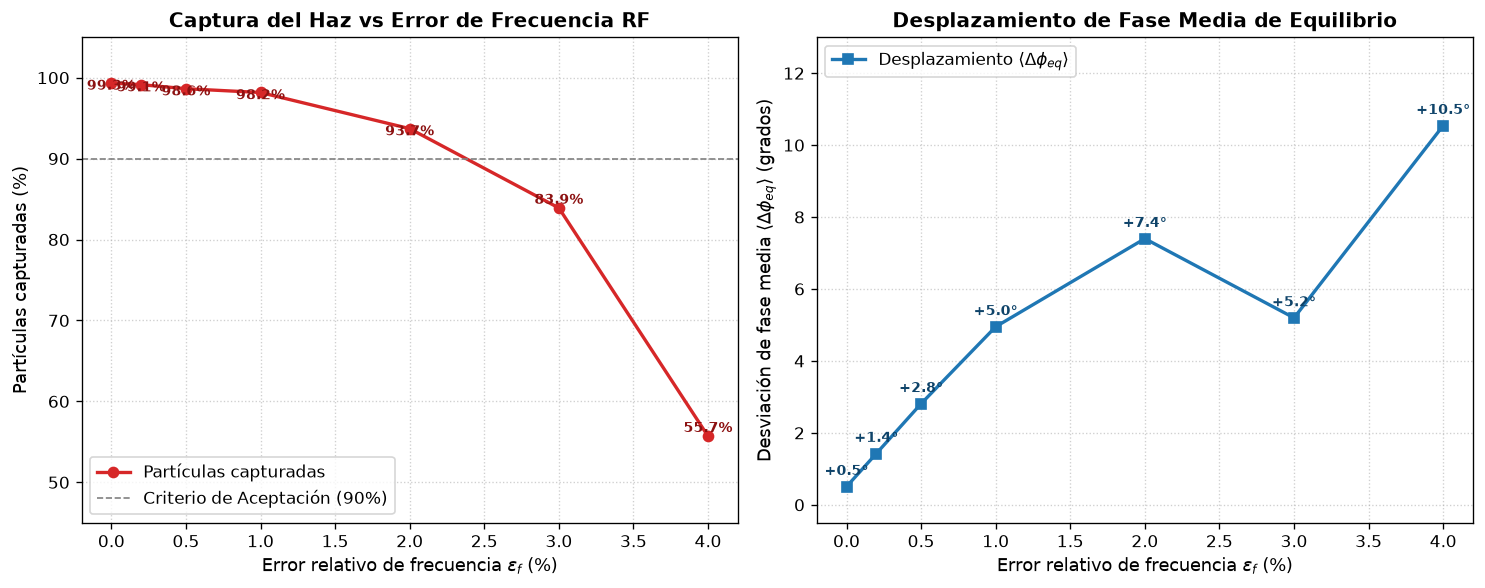

 Datos de sensibilidad de RF exportados a 'resultados/rf_errores_sensibilidad.csv'


In [7]:
# Simular barrido de errores de frecuencia RF
rf_results, _ = simulate_frequency_errors(error_list=[0.0, 0.002, 0.005, 0.01, 0.02, 0.03, 0.04])

# Graficar y exportar a CSV
plot_rf_error_results(rf_results)
export_rf_errors_to_csv(rf_results, filename="resultados/rf_errores_sensibilidad.csv")

## 6. Dinámica Comparativa con Electrones Relativistas
A diferencia de los protones, los electrones inyectados a $T_0 = 10.0\text{ MeV}$ poseen una velocidad inicial $\beta_0 \approx 0.9988$ (ultrarelativistas). Por ello:
1. Se utiliza una estructura con celdas de longitud constante $L = \lambda$.
2. No existen oscilaciones de sincrotrón (se congelan en fase).
3. La ganancia de energía depende directamente del coseno de la fase de inyección $\Delta T \propto \cos(\phi_0)$.

      SIMULACIÓN DE ELECTRONES RELATIVISTAS (10 MeV, 60 celdas)  
Fase Inyección (°) | Energía Final (MeV) | Deriva Total de Fase (°)
-----------------------------------------------------------------
     -40.0°        |      58.12 MeV     |       +4.45°
     -20.0°        |      67.34 MeV     |       +3.78°
     +0.0 °        |      69.92 MeV     |       +3.61°
     +20.0°        |      65.25 MeV     |       +3.85°
     +40.0°        |      53.55 MeV     |       +4.67°

Gráfica guardada exitosamente en 'figuras/fig05_estabilidad_electrones.png'


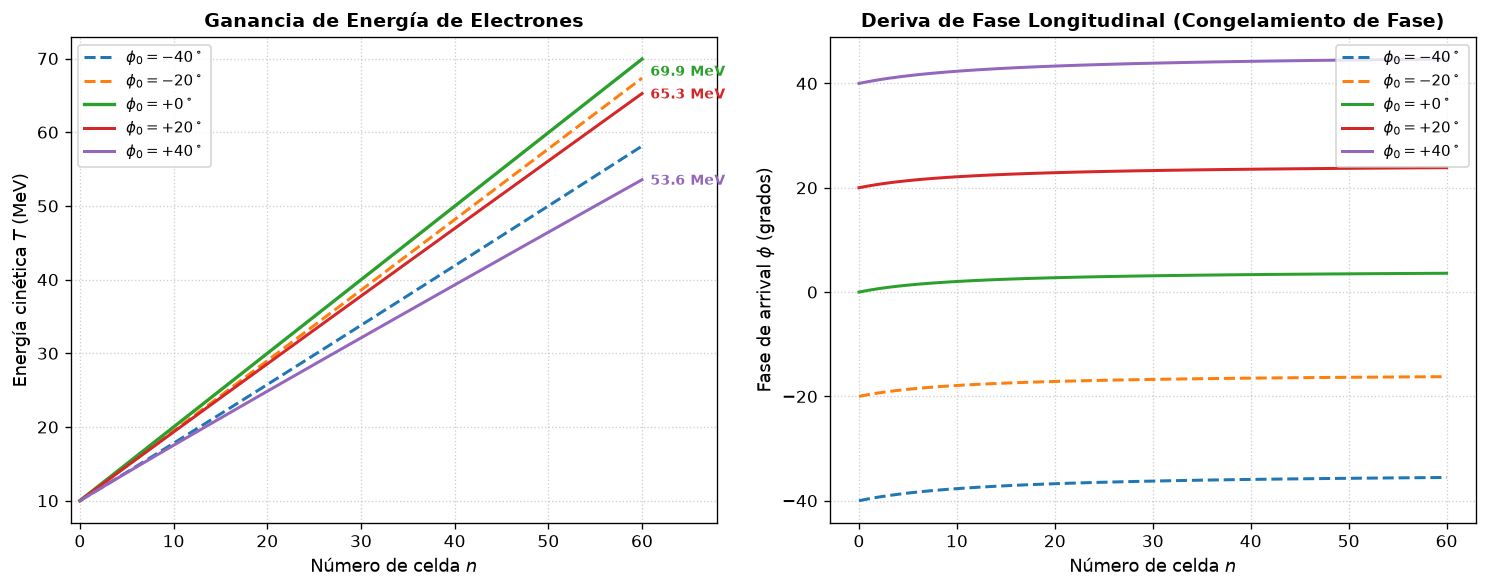

 Datos de electrones exportados a 'resultados/electrones_simulacion.csv'


In [8]:
# Simular electrones en 60 celdas constantes
e_hist_T, e_hist_phi, e_phases = simulate_electrons(T_0=10.0, num_cells=60)

# Graficar y exportar a CSV
plot_electron_results(e_hist_T, e_hist_phi, e_phases)
export_electrons_to_csv(e_hist_T, e_hist_phi, e_phases, filename="resultados/electrones_simulacion.csv")

### Eficiencia Aceleradora Espacial ($dT/dz$)
Mientras que en la cavidad tipo Álvarez para protones el gradiente de energía por metro decae drásticamente desde $11.24\text{ MeV/m}$ hasta $3.22\text{ MeV/m}$ debido al crecimiento continuo del tamaño de las celdas ($L_n = \beta_n \lambda$), la estructura para electrones ultrarelativistas opera con una celda constante $L = \lambda \approx 0.851\text{ m}$. Esto permite mantener una aceleración perfectamente uniforme por unidad de longitud de $dT/dz \approx 1.17\text{ MeV/m}$.

Gráfica guardada en 'figuras\fig09_tasa_ganancia_energia.png'


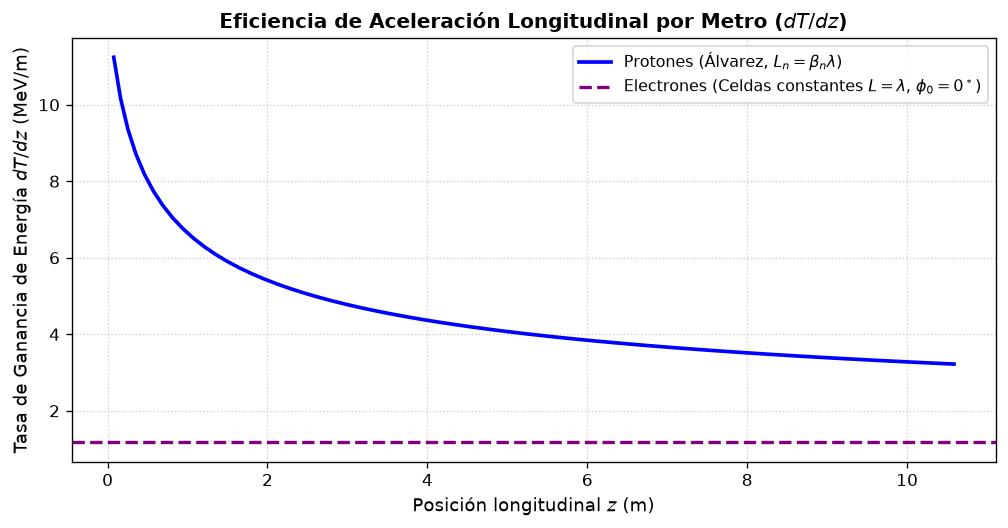

In [9]:
# Importar y ejecutar la gráfica de ganancia por metro
from src.visualizer import plot_energy_gain_rate

df_diseno = pd.read_csv("resultados/diseno_celdas.csv")

plot_energy_gain_rate(
    z_positions=z_positions,
    Eacc_vals=df_diseno["E_acc_MV_m"].values,
    f_rf=352.2e6,
    save_fig=True,
    filename="fig09_tasa_ganancia_energia.png",
)

### AGREGADO 1: Campo electrico y velocidad relativista

Gráfica guardada en 'figuras\fig06_perfil_campos.png'


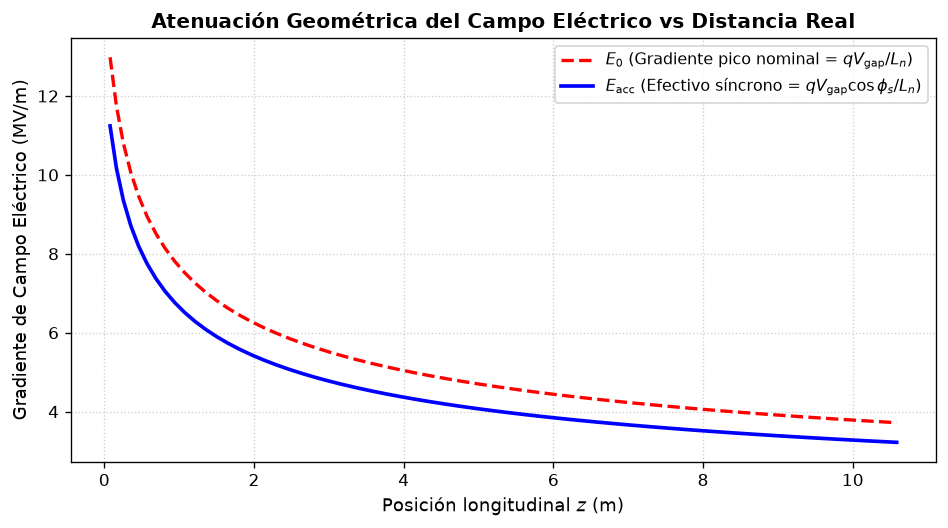

Gráfica guardada correctamente en 'figuras\fig08_perfil_cinematico.png'


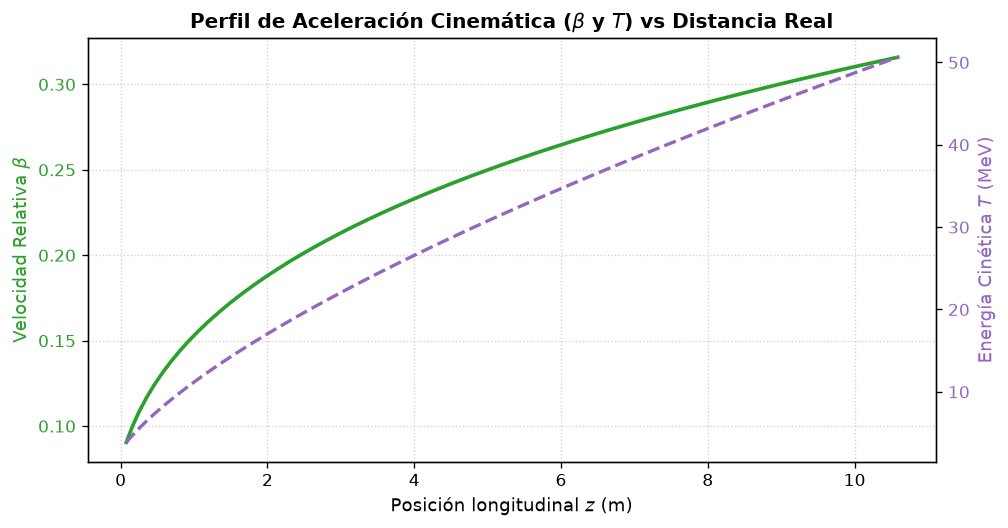

Gráfica guardada en 'figuras\fig07_amortiguamiento_cuantitativo.png'


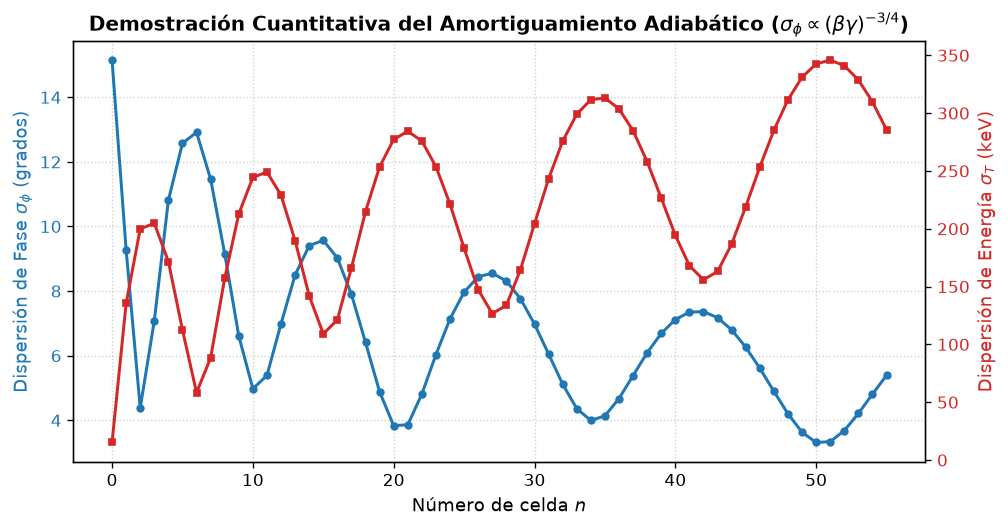

In [10]:

from src.visualizer import plot_electric_field_profile, plot_adiabatic_damping_evolution, plot_kinematic_profile

# Cargar datos del diseño y campos
df_diseno = pd.read_csv("resultados/diseno_celdas.csv")

# 1. Graficar perfil de campos eléctricos en metros reales
plot_electric_field_profile(
    z_positions=z_positions,
    E0_vals=df_diseno["E0_MV_m"].values,
    Eacc_vals=df_diseno["E_acc_MV_m"].values,
)

# 3. Ejecutar la gráfica cinemática
plot_kinematic_profile(
    z_positions=z_positions,
    beta_vals=df_diseno["Beta"].values,
    T_sync=T_sync,)

# 2. Graficar la evolución cuantitativa del amortiguamiento adiabático
plot_adiabatic_damping_evolution(hist_T, hist_phi, T_sync, phi_s_deg=-30.0)



## 7. Conclusiones del Proyecto
1. **Diseño Geométrico:** La aceleración de protones exige un incremento de longitud de celdas desde $7.73\text{ cm}$ hasta $26.83\text{ cm}$ para preservar la condición de sincronismo $L_n = \beta_n \lambda$.
2. **Estabilidad de Fase:** La captura longitudinal supera el $99\%$ para el haz nominal. Las oscilaciones de sincrotrón se amortiguan en un factor $\approx 2.15$.
3. **Tolerancia de Frecuencia:** El acelerador tolera errores de frecuencia de hasta $\approx 1.0\%$ con capturas superiores al $98\%$. Errores mayores al $3\%$ degradan la captura severamente.
4. **Régimen Ultrarelativista:** Los electrones no requieren celdas de tamaño variable y muestran un congelamiento de fase asintótico sin oscilaciones longitudinales.